<a href="https://colab.research.google.com/github/Ghazal-Rouhani/DSC_110/blob/main/ML_Model_Building.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **Model Building**

This notebook will be divided into 2 main parts

Part 1: concepts

Part 2: applying those concepts to the real NHANES dataset that we cleaned in week 8

**Part 1: Concepts**

Linear Regression

We import pandas to organize our data and LinearRegression to build a prediction model. We use age as our input (X) and the example values as our target (y).
We create and train a linear regression model to learn how the target changes with age. Then we use the trained model to predict values for ages it has not seen before.

In [ ]:
import pandas as pd
from sklearn.linear_model import LinearRegression

X = pd.DataFrame({'age': [20, 30, 40, 50, 60]})
y = [110, 115, 120, 125, 130]

lr = LinearRegression()
lr.fit(X, y)

ages_to_predict = pd.DataFrame({'age': [10, 45, 80]})
predictions = lr.predict(ages_to_predict)
print(predictions)

[105.  122.5 140. ]


We loop through the predictions and print each one with two decimal places. This makes the results easier to read.

In [ ]:
#Use loop to print predictions cleanly (with 2 decimals)
for p in predictions:
    print(f"{p:.2f}")

105.00
122.50
140.00


We now try linear regression with a target that only has two values: 0 and 1. We train the model and predict outcomes for three new ages. This example helps us see why linear regression is not ideal for binary outcomes: its predictions are not limited to 0 or 1.

In [ ]:
#Let's apply linear regression when the output is binary (0 and 1)
X = pd.DataFrame({'age': [20, 30, 40, 50, 60, 70]})
y = [0, 0, 0, 1, 1, 1]

lr = LinearRegression()
lr.fit(X, y)

ages_to_predict = pd.DataFrame({'age': [5, 45, 100]})
predictions = lr.predict(ages_to_predict)

for p in predictions:
    print(f"{p:.2f}")

-0.53
0.50
1.91


Logistic Regression

to make predictions between 0 and 1 for binary outcomes

We import logistic regression and use age to predict a binary outcome (0 or 1) and train the model using the example ages and their labels. We use predict_proba() to get the probability of each class for new ages. We print the probability of class 1, rounded to two decimal places.

In [ ]:
#Logistic regression
from sklearn.linear_model import LogisticRegression
import numpy as np

X = pd.DataFrame({'age': [20, 30, 40, 50, 60, 70]})
y =                       [0,  0,  0,  1,  1,  1]

lr = LogisticRegression()
lr.fit(X, y)

ages_to_predict = pd.DataFrame({'age': [5, 45, 100]})

probabilities = lr.predict_proba(ages_to_predict)

for p in probabilities[:, 1]:
    print(f"{p:.2f}")

0.00
0.50
1.00


We test logistic regression with an example where class 1 appears in the middle age range. We fit the model and estimate the probability of class 1 for new ages. This helps us see that a simple logistic regression model may struggle with a pattern that is not a straight increasing or decreasing trend.

In [ ]:
#Logistic regression when the outcome is not linear
from sklearn.linear_model import LogisticRegression
import pandas as pd

X = pd.DataFrame({'age': [20, 30, 40, 50, 60, 70, 80]})
y =  [0,  0,  1,  1,  1,  0,  0]

lr = LogisticRegression()
lr.fit(X, y)

ages_to_predict = pd.DataFrame({'age': [25, 50, 75]})
probabilities = lr.predict_proba(ages_to_predict)

for p in probabilities[:, 1]:
    print(f"{p:.2f}")

0.43
0.43
0.43


Decision Tree

We import a decision tree classifier to predict categories using simple decision rules. We train the tree using ages and binary labels. We predict the class for three new ages and print the results. Decision trees can split age into ranges, which may help with patterns that are not linear.

In [ ]:
from sklearn.tree import DecisionTreeClassifier

X = pd.DataFrame({'age': [20, 30, 40, 50, 60, 70, 80]})
y =  [0,  0,  1,  1,  1,  0,  0]

dt = DecisionTreeClassifier()
dt.fit(X, y)

ages_to_predict = pd.DataFrame({'age': [25, 50, 75]})
probabilities = dt.predict(ages_to_predict)

for p in probabilities:
    print(f"{p:.2f}")

0.00
1.00
0.00


We import tools to draw the decision tree we trained above. We set the figure size and show each split using the age feature. We label the two classes as No Diabetes and Diabetes to make the example easier to understand. We display the plot so we can see how the tree makes its decisions.

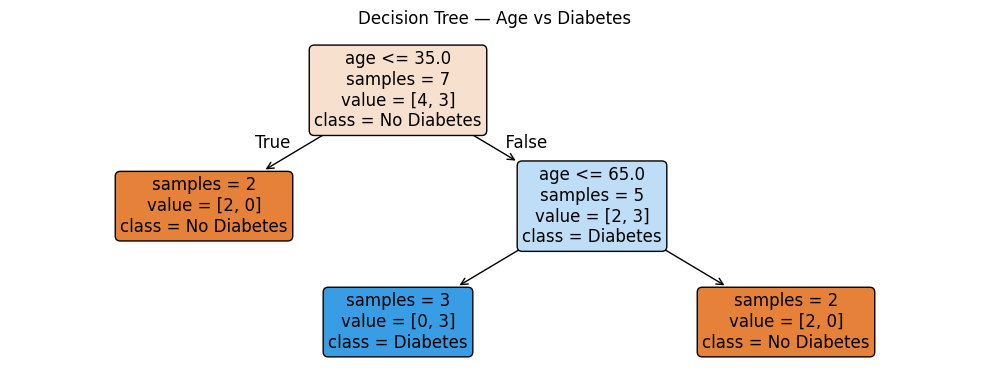

In [ ]:
#Visualize the Decision Tree (DEMO only)
#Visualize the tree (demo only)
from sklearn.tree import plot_tree
import matplotlib.pyplot as plt

# Visualize the tree
plt.figure(figsize=(10, 4))

plot_tree(dt,
          feature_names=['age'],
          class_names=['No Diabetes', 'Diabetes'],
          filled=True,
          rounded=True,
          fontsize=12,
          impurity=False,
          precision=0)
plt.title('Decision Tree — Age vs Diabetes')
plt.tight_layout()
plt.show()

**Part 2: NHANES dataset**

We import the libraries needed to load data, train different machine learning models, and visualize results. We will compare logistic regression, decision tree, random forest, XGBoost, and a neural network. We also import confusion matrix tools to see how well each model predicts diabetes.

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.ensemble import RandomForestClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
from xgboost import XGBClassifier

We load the training and testing datasets from the course GitHub repository. X contains the input features, while y contains the diabetes labels we want to predict. We keep training and testing data separate so we can evaluate models on data they did not learn from. We use squeeze() to turn the one-column label tables into one-dimensional Series, which is the format many models expect.

In [ ]:
X_train = pd.read_csv('https://raw.githubusercontent.com/osoliman/DSC110/refs/heads/main/Datasets/X_train.csv')
X_test = pd.read_csv('https://raw.githubusercontent.com/osoliman/DSC110/refs/heads/main/Datasets/X_test.csv')
y_train = pd.read_csv('https://raw.githubusercontent.com/osoliman/DSC110/refs/heads/main/Datasets/y_train.csv')
y_test = pd.read_csv('https://raw.githubusercontent.com/osoliman/DSC110/refs/heads/main/Datasets/y_test.csv')

#to prevent warning, converting the y from df to 1d series
y_train = y_train.squeeze()
y_test  = y_test.squeeze()

 We put the names of our four datasets into a list and loop through them. We use globals() to find each dataset by its name and print its shape. This lets us check the number of rows and columns before training our models.

In [ ]:
#Verifiying files via a loop
files = ['X_train','X_test','y_train','y_test']

for file_name in files:
  # Access the actual DataFrame object using its name from the global scope
  df = globals()[file_name]
  print(df.shape)

(6018, 15)
(1505, 15)
(6018,)
(1505,)


Logistic Regression

We create a logistic regression model. We use fit() to train it on the training features and diabetes labels. The model learns patterns that can help predict whether a patient has diabetes.

In [ ]:
#fit is the keyword
lr = LogisticRegression()
lr.fit(X_train, y_train)

LogisticRegression()

We choose one patient from the test dataset using row position 243. We use double brackets to keep this patient's information as a DataFrame, which the model can predict from.

In [ ]:
#Picking one patient to see their actual and predicted value
patient = X_test.iloc[[243]]
patient

,age,bmi,height_cm,systolic_bp,gender_Male,race_ethnicity_Black,race_ethnicity_Mexican American,race_ethnicity_Other,race_ethnicity_Other Hispanic,race_ethnicity_White,education_College grad,education_Do not know,education_High school,education_Less than 9th,education_Some college
243,0.776425,1.479961,-0.391115,1.444984,False,False,False,False,False,True,False,False,True,False,False


We get the actual diabetes label for the same patient from y_test. We print the label so we can compare the real result with the model's prediction. In this dataset, 1 means diabetes and 0 means no diabetes.

In [ ]:
#Seeing the actual label for the same patient: #1 means the patient has diabetes
actual = y_test.iloc[243]
print(actual)

1


We use our trained logistic regression model to predict the selected patient's label. We take the first prediction with [0] and print it to compare with the actual label.

In [ ]:
#Seeing what the logistic regression model did for this patient
prediction = lr.predict(patient)[0]
print(prediction)

0


We predict diabetes labels for every patient in the test dataset. We show a confusion matrix to compare predicted labels with actual labels. This helps us see correct predictions as well as false positives and false negatives.

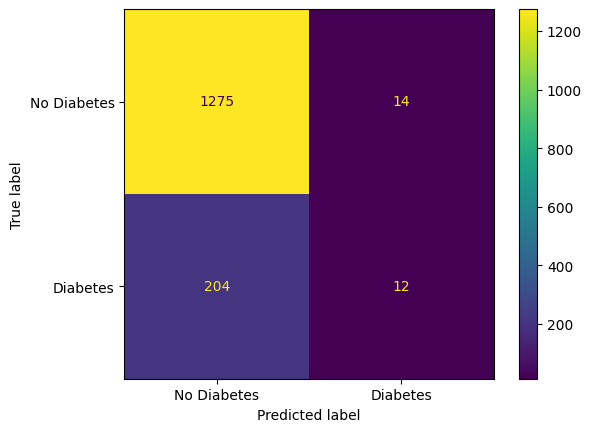

In [ ]:
#Seeing this for all patients: done through what's called "Confusion Matrix"
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

y_pred = lr.predict(X_test)
ConfusionMatrixDisplay.from_predictions(y_test, y_pred, display_labels=['No Diabetes', 'Diabetes'])
plt.show()

Decision Tree

We create a decision tree classifier and set random_state=42 so our results are reproducible. We train the decision tree using the same training data as logistic regression. The tree learns decision rules based on the input features.

In [ ]:
dt = DecisionTreeClassifier(random_state=42) #random state used for reproducibility
dt.fit(X_train, y_train)

DecisionTreeClassifier(random_state=42)

We use the trained decision tree to predict diabetes for the same selected patient. We print the prediction so we can compare it with the other models.

In [ ]:
#Predicting the outcome for the same patient we picked in the top
prediction = dt.predict(patient)[0]
print(prediction)

0


We predict all test patients with the decision tree. We display a confusion matrix to check its correct and incorrect classifications.

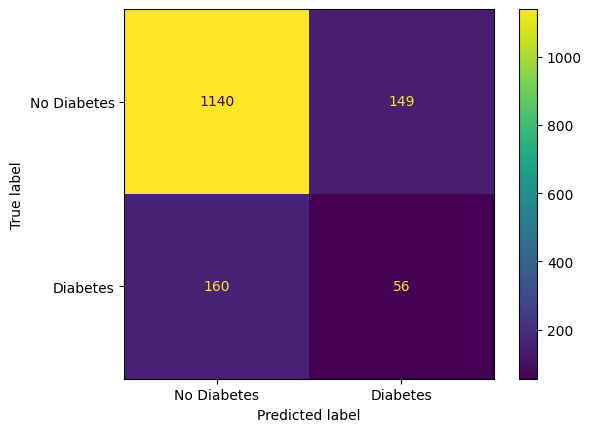

In [ ]:
y_pred = dt.predict(X_test)
ConfusionMatrixDisplay.from_predictions(y_test, y_pred, display_labels=['No Diabetes', 'Diabetes'])
plt.show()

Random Forest

We create a random forest classifier with a fixed random state for reproducibility. A random forest combines predictions from many decision trees. We train it on the same training data to compare its performance with the other models.

In [ ]:
rf = RandomForestClassifier(random_state=42)
rf.fit(X_train, y_train)

RandomForestClassifier(random_state=42)

We use the trained random forest to predict the selected patient's diabetes label. We print the result to compare it with the previous predictions.

In [ ]:
prediction = rf.predict(patient)[0]
print(prediction)

1


We make predictions for the entire test dataset using the random forest. We display a confusion matrix to see how many labels it predicted correctly and incorrectly.

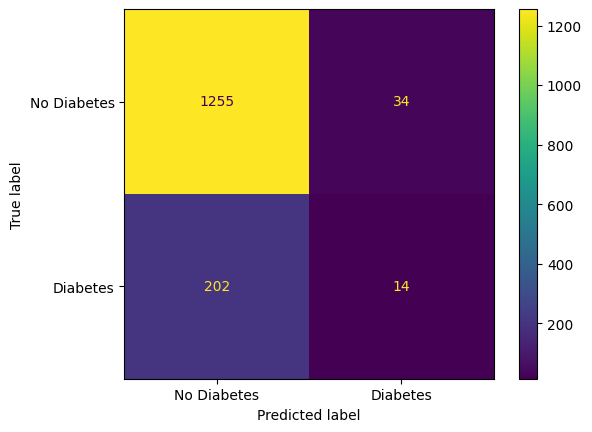

In [ ]:
y_pred = rf.predict(X_test)
ConfusionMatrixDisplay.from_predictions(y_test, y_pred, display_labels=['No Diabetes', 'Diabetes'])
plt.show()

XGBoost

We create an XGBoost classifier with a fixed random state. XGBoost builds trees in sequence, with later trees helping correct earlier errors. We train it on the same data so we can compare it with the other models.

In [ ]:
xgb = XGBClassifier(random_state=42)
xgb.fit(X_train, y_train)

XGBClassifier(base_score=None, booster=None, callbacks=None,
              colsample_bylevel=None, colsample_bynode=None,
              colsample_bytree=None, device=None, early_stopping_rounds=None,
              enable_categorical=False, eval_metric=None, feature_types=None,
              feature_weights=None, gamma=None, grow_policy=None,
              importance_type=None, interaction_constraints=None,
              learning_rate=None, max_bin=None, max_cat_threshold=None,
              max_cat_to_onehot=None, max_delta_step=None, max_depth=None,
              max_leaves=None, min_child_weight=None, missing=nan,
              monotone_constraints=None, multi_strategy=None, n_estimators=None,
              n_jobs=None, num_parallel_tree=None, ...)

We use XGBoost to predict the diabetes label for our selected patient. We print the result to compare it with the other models.

In [ ]:
prediction = xgb.predict(patient)[0]
print(prediction)

1


We use XGBoost to predict labels for all test patients. We display a confusion matrix to evaluate its predictions.

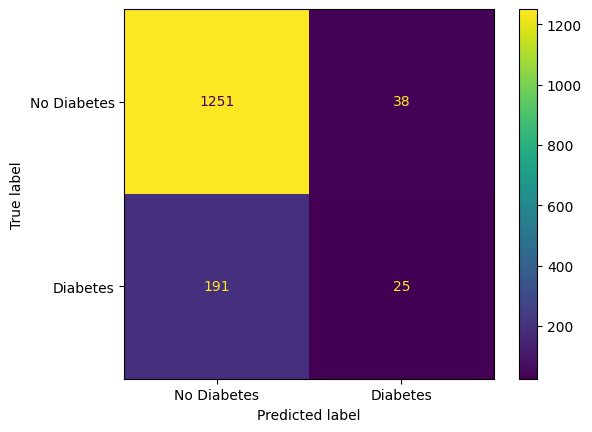

In [ ]:
y_pred = xgb.predict(X_test)
ConfusionMatrixDisplay.from_predictions(y_test, y_pred, display_labels=['No Diabetes', 'Diabetes'])
plt.show()

Neural Networks

We create a neural network classifier using MLPClassifier. We set random_state=42 for reproducibility and max_iter=500 as the maximum number of training iterations. We train the network to learn relationships between the patient features and diabetes labels.

In [ ]:
nn = MLPClassifier(random_state=42, max_iter=500)
nn.fit(X_train, y_train)

/usr/local/lib/python3.12/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (500) reached and the optimization hasn't converged yet.
  warnings.warn(


MLPClassifier(max_iter=500, random_state=42)

We use our trained neural network to predict the selected patient's label. We print it to compare with the actual result and the other models.

In [ ]:
prediction = nn.predict(patient)[0]
print(prediction)

0


We predict labels for all test patients with the neural network. We display a confusion matrix to review correct predictions and errors. We can compare these matrices across models to see how their predictions differ.

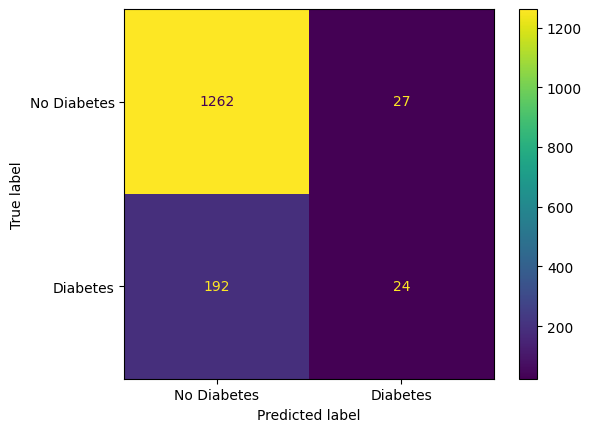

In [ ]:
y_pred = nn.predict(X_test)
ConfusionMatrixDisplay.from_predictions(y_test, y_pred, display_labels=['No Diabetes', 'Diabetes'])
plt.show()